# TP 4: Information Retrieval Models

```(Scoring, Term Weighting and the Vector Space Model)```

## Problem Set:

- Learn how to create and interpret a Term Document Matrix (TDM) for a set of documents. And apply the Vector Space Model to calculate document similarity using cosine similarity.

## Problem 1: Create a Term Document Matrix

### Task: Create a Term Document Matrix for a small set of documents.

### Instructions:

#### 1. Choose the following three sample documents:
- Document 1: ```Data science combines statistics, computer science, and domain knowledge.```

- Document 2: ```Machine learning algorithms can analyze large datasets and make predictions.```

- Document 3: ```Data visualization helps in interpreting complex data and communicating insights.```


In [1]:
DOCS = [
    "Data science combines statistics, computer science, and domain knowledge.",
    "Machine learning algorithms can analyze large datasets and make predictions.",
    "Data visualization helps in interpreting complex data and communicating insights."
]

#### 2. Write a function to tokenize each document (split into words) and count the frequency of each term.


In [2]:
import re  # Load the tool for finding words using a text rule.
from collections import Counter  # Load the tool for counting repeated items.

def tokenize1(text): # Make a function that takes one document and return tokenize and freq count
    text = text.lower()
    words = re.findall(r"[a-z]+", text)
    counts = Counter(words)
    return counts

# apply the function
term_counts = []
for doc_id, doc in enumerate(DOCS, start=1):
    counts = tokenize1(doc)
    term_counts.append(counts)
    print("Document", doc_id, ":", dict(counts))

Document 1 : {'data': 1, 'science': 2, 'combines': 1, 'statistics': 1, 'computer': 1, 'and': 1, 'domain': 1, 'knowledge': 1}
Document 2 : {'machine': 1, 'learning': 1, 'algorithms': 1, 'can': 1, 'analyze': 1, 'large': 1, 'datasets': 1, 'and': 1, 'make': 1, 'predictions': 1}
Document 3 : {'data': 2, 'visualization': 1, 'helps': 1, 'in': 1, 'interpreting': 1, 'complex': 1, 'and': 1, 'communicating': 1, 'insights': 1}


#### 3. Construct the Term Document Matrix (TDM) and print it.

In [3]:
# Collect all different words, then sort them in letter order.
word_set = set()
for counts in term_counts:
    word_set.update(counts.keys())
vocab = sorted(word_set)

# Build one row of word counts for each document.
TDM = []
for counts in term_counts:
    row = []
    for term in vocab:
        row.append(counts[term]) # Counter gives 0 if the word is absent
    TDM.append(row)

# Print the column names, followed by each document's row.
print("Terms:", vocab)
for doc_id, row in enumerate(TDM, start=1):
    print("Document", doc_id, ":", row)



Terms: ['algorithms', 'analyze', 'and', 'can', 'combines', 'communicating', 'complex', 'computer', 'data', 'datasets', 'domain', 'helps', 'in', 'insights', 'interpreting', 'knowledge', 'large', 'learning', 'machine', 'make', 'predictions', 'science', 'statistics', 'visualization']
Document 1 : [0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 2, 1, 0]
Document 2 : [1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0]
Document 3 : [0, 0, 1, 0, 0, 1, 1, 0, 2, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1]


## Problem 2: Visualize the Term Document Matrix
### Task: Display the Term Document Matrix in a readable format.
### Instructions:
#### 1. Using the TDM created in Problem 1, format the matrix into a table.


In [4]:
import pandas as pd
table = pd.DataFrame(TDM, columns=vocab)
table

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,...,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
0,0,0,1,0,1,0,0,1,1,0,...,0,1,0,0,0,0,0,2,1,0
1,1,1,1,1,0,0,0,0,0,1,...,0,0,1,1,1,1,1,0,0,0
2,0,0,1,0,0,1,1,0,2,0,...,1,0,0,0,0,0,0,0,0,1


#### 2. Ensure that the rows represent documents and the columns represent terms.

In [5]:
# Show the labels used for rows and columns.
print("Rows (documents):", table.index.tolist())
print("Columns (words):", table.columns.tolist())

# Show how many rows and columns the table has.
print("Number of rows:", table.shape[0])
print("Number of columns:", table.shape[1])

Rows (documents): [0, 1, 2]
Columns (words): ['algorithms', 'analyze', 'and', 'can', 'combines', 'communicating', 'complex', 'computer', 'data', 'datasets', 'domain', 'helps', 'in', 'insights', 'interpreting', 'knowledge', 'large', 'learning', 'machine', 'make', 'predictions', 'science', 'statistics', 'visualization']
Number of rows: 3
Number of columns: 24


#### 3. Print the TDM with appropriate labels for documents and terms.

In [6]:
# rename the row
table.index = ["doc1", "doc2", "doc3"]

# Show every word column when displaying this table.
with pd.option_context("display.max_columns", None):
    display(table)

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,domain,helps,in,insights,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0,0,1,0,1,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,2,1,0
doc2,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,1,1,1,1,0,0,0
doc3,0,0,1,0,0,1,1,0,2,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1


## Problem 3: Implement TF-IDF
### Task: Calculate TF-IDF weights for the terms in the TDM.
### Instructions:
#### 1. Using the TDM from Problem 1, write a function to calculate the TF-IDF for each term in each document (Lecture 4, N = 3):
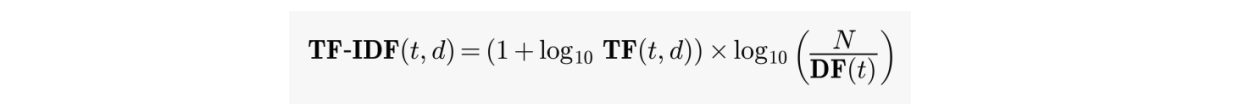

#### Personal Notation:

The task gives this formula:

```TF-IDF = (1 + log₁₀(TF)) × log₁₀(N / DF)```

- TF: how many times the word appears in the current document.
- DF: how many documents contain the word.
- N: total number of documents—here, 3.

If a word is absent, its weight is 0. We handle that separately because log₁₀(0) cannot be calculated.

In [7]:
import math 
def calculate_tfidf(count_table):
    N = len(count_table) # count doc rows

    # Make a separate table that can hold decimal weights.
    weights = count_table.astype(float).copy()

    for term in count_table.columns:
        # count the doc were this word appears.
        df  = (count_table[term]>0).sum()
        idf = math.log10(N / df)

        for doc in count_table.index:
            tf = count_table.loc[doc, term] # read this word's count in this doc
            if tf == 0:
                weights.loc[doc, term] = 0
            else :
                weights.loc[doc, term] = (
                    (1+math.log10(tf)) * idf 
                )
    return weights

# Apply the function to our word-count table.
tfidf_table = calculate_tfidf(table)
tfidf_table

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,...,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0.000000,0.000000,0.0,0.000000,0.477121,0.000000,0.000000,0.477121,0.176091,0.000000,...,0.000000,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.620749,0.477121,0.000000
doc2,0.477121,0.477121,0.0,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.477121,...,0.000000,0.000000,0.477121,0.477121,0.477121,0.477121,0.477121,0.000000,0.000000,0.000000
doc3,0.000000,0.000000,0.0,0.000000,0.000000,0.477121,0.477121,0.000000,0.229100,0.000000,...,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.477121


#### 2. Display the TF-IDF matrix.

In [8]:
# Show all word columns, with weights rounded to three decimal places.
with pd.option_context("display.max_columns", None):
    display(tfidf_table.round(3))


,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,domain,helps,in,insights,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0.000,0.000,0.0,0.000,0.477,0.000,0.000,0.477,0.176,0.000,0.477,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.621,0.477,0.000
doc2,0.477,0.477,0.0,0.477,0.000,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.477,0.477,0.477,0.477,0.477,0.000,0.000,0.000
doc3,0.000,0.000,0.0,0.000,0.000,0.477,0.477,0.000,0.229,0.000,0.000,0.477,0.477,0.477,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.477


## Problem 4: Calculate Cosine Similarity

### Task: Compute the cosine similarity between a query and the documents.

### Instructions:

#### 1. Define a query, for example: "data science algorithms".

In [11]:
query = "data science algorithms"

#### 2. Write a function to convert the query into a vector based on the terms in the TF-IDF matrix

In [14]:
def query_2_vector(query, count_table):
    query_counts = tokenize1(query)
    N = len(count_table)
    vector = []

    # Follow the same word order as the document table.
    for term in count_table.columns:
        tf = query_counts[term]

        if tf == 0:
            vector.append(0)
        else:
            # Use document counts from our collection to calculate IDF.
            df = (count_table[term] > 0).sum()
            idf = math.log10(N/df)
            weight = (1+math.log10(tf)) * idf
            vector.append(weight)
    return vector

# Convert the query and show its non-zero weights.
query_vector = query_2_vector(query, table)

for term, weight in zip(table.columns, query_vector):
    if weight > 0:
        print(term, "->", round(weight, 3))

algorithms -> 0.477
data -> 0.176
science -> 0.477


#### 3. Implement the cosine similarity formula: 

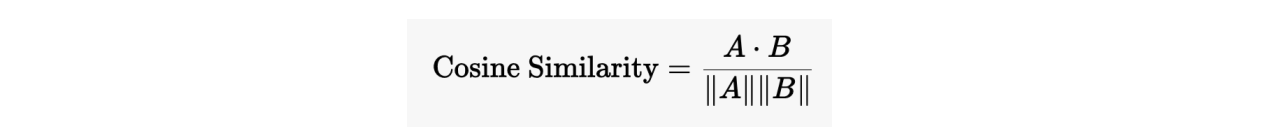

where A is the query vector and B is the document vector.

In [15]:
def cosine_similarity(A, B):
    # Multiply matching weights, then add the products.
    dot_product = sum(a * b for a, b in zip(A, B))

    # Find each vector's length: square its weights, add them, then take the square root.
    length_A = math.sqrt(sum(a ** 2 for a in A))
    length_B = math.sqrt(sum(b ** 2 for b in B))

    # Avoid dividing by zero if either vector has no weight.
    if length_A == 0 or length_B == 0:
        return 0.0

    return dot_product / (length_A * length_B)

#### 4. Rank the documents based on their cosine similarity to the query and print the results.

In [ ]:
# query = "bruh"

# Calculate one similarity score for each document.
scores = []

for doc_name, row in tfidf_table.iterrows():
    doc_vector = row.tolist()  # Turn the document's word weights into a list.
    score = cosine_similarity(query_vector, doc_vector)
    scores.append((doc_name, score))

# Sort by score, with the highest score first.
ranked_results = sorted(
    scores,
    key=lambda item: item[1],  # Each item's second value is its score.
    reverse=True
)

# Print the documents in rank order.
print("Query:", query)

for rank, (doc_name, score) in enumerate(ranked_results, start=1):
    print(f"{rank}. {doc_name}: {score:.4f}")

Query: 
1. doc1: 0.3763
2. doc2: 0.2281
3. doc3: 0.0451


## Problem 5: Advanced Query Processing and Cosine Similarity

### Task: Preprocess documents and queries, then calculate cosine similarity with enhanced text normalization techniques.

### Instructions:

#### 1. Define multiple queries, for example:
- Query 1: "data scientist"
- Query 2: "machine learn"
- Query 3: "visualization of data"

In [22]:
Qeuries = [
    "data scientist",
    "machine learn",
    "visualization of data"
]

#### 2. Implement the following steps:

> Text Normalization: Preprocess the documents and queries by:

- Converting text to lowercase.
- Removing punctuation.
- Applying stemming (using NLTK or a similar library).

> Write a Python function to:

- Convert each preprocessed query into a vector based on the terms in the TF-IDF matrix.
- Calculate cosine similarity for each query against all documents.
- Rank the documents for each query based on their similarity scores and print the results.

In [26]:
# 1- Convert text ot lowers
# 2- Remove punctuation
# 3- Apply stemming (reduce word forms using rules)

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def preprocess(text):
    # use small letters and keep only group of letters 
    words = re.findall(r'[a-z]+', text.lower())

    # apply porter stemming to each word 
    terms = []

    for word in words:
        terms.append(stemmer.stem(word))
    
    return terms

# clean the doc and show the resulting terms
processed_docs = []

for doc_id, doc in enumerate(DOCS, start=1):
    terms = preprocess(doc)
    processed_docs.append(terms)
    print("Document", doc_id, ":", terms)

# show how the same rules change each query 
for query in Qeuries:
    print(query, "->", preprocess(query))

Document 1 : ['data', 'scienc', 'combin', 'statist', 'comput', 'scienc', 'and', 'domain', 'knowledg']
Document 2 : ['machin', 'learn', 'algorithm', 'can', 'analyz', 'larg', 'dataset', 'and', 'make', 'predict']
Document 3 : ['data', 'visual', 'help', 'in', 'interpret', 'complex', 'data', 'and', 'commun', 'insight']
data scientist -> ['data', 'scientist']
machine learn -> ['machin', 'learn']
visualization of data -> ['visual', 'of', 'data']


In [25]:
# 1. Rebuild the word-count and TF-IDF tables using the stemmed documents.
# 2. Turn each query into weights using the same stemming rules.
# 3. Calculate cosine similarity against each document.
# 4. Rank and print the results for all three queries.

# Count the stemmed terms in each document.
stemmed_counts = []

for terms in processed_docs:
    stemmed_counts.append(Counter(terms))

# Collect all different stemmed terms and sort them.
stemmed_word_set = set()

for counts in stemmed_counts:
    stemmed_word_set.update(counts.keys())

stemmed_vocab = sorted(stemmed_word_set)

# Build the word-count rows using the new term order.
stemmed_TDM = []

for counts in stemmed_counts:
    row = []

    for term in stemmed_vocab:
        row.append(counts[term])

    stemmed_TDM.append(row)

# Add document and term labels.
stemmed_table = pd.DataFrame(
    stemmed_TDM,
    index=table.index,
    columns=stemmed_vocab
)

# Use our earlier function to calculate the new TF-IDF weights.
stemmed_tfidf = calculate_tfidf(stemmed_table)

# Display the weights for all stemmed terms.
with pd.option_context("display.max_columns", None):
    display(stemmed_tfidf.round(3))

,algorithm,analyz,and,can,combin,commun,complex,comput,data,dataset,domain,help,in,insight,interpret,knowledg,larg,learn,machin,make,predict,scienc,statist,visual
doc1,0.000,0.000,0.0,0.000,0.477,0.000,0.000,0.477,0.176,0.000,0.477,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.621,0.477,0.000
doc2,0.477,0.477,0.0,0.477,0.000,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.477,0.477,0.477,0.477,0.477,0.000,0.000,0.000
doc3,0.000,0.000,0.0,0.000,0.000,0.477,0.477,0.000,0.229,0.000,0.000,0.477,0.477,0.477,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.477
